<a href="https://colab.research.google.com/github/Taheri1400/deep-learning-projects/blob/main/apply.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 dir=rtl align=center style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
اپلای
</font>
</h1>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
در این تمرین قصد داریم با استفاده از مفاهیم اولیه‌ای که از تنسورفلو آموختیم به پیاده‌سازی یک مدل ساده‌ی رگرسیون خطی بپردازیم. به این بهانه، مدلی آموزش خواهیم داد که شانس پذیرش تحصیلی یک فرد را با توجه به رزومه‌ی وی تخمین بزند.
</font>
</p>

In [1]:
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import tensorflow as tf

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
مجموعه‌داده
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
مجموعه‌داده‌ای که در اختیار شما قرار گرفته شامل پارامترهای مختلفی‌ست که جهت اخذ پذیرش مقطع ارشد در دانشگاه‌های خارج از کشور مورد بررسی قرار می‌گیرند. متغیر هدف این مسئله، شانس گرفتن پذیرش است که می‌تواند عددی بین ۰ تا ۱ باشد، یعنی مدل شما باید بتواند با دریافت یک‌سری مشخصات عددی از رزومه‌ی فرد، شانس پذیرش وی را تخمین بزند. هر کدام از ویژگی‌های این مجموعه‌داده در جدول زیر شرح داده شده است.
</font>
</p>


<center>
<div dir=rtl style="direction: rtl;line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>

| نام ستون | توضیحات ستون | بازه‌ی مقادیر |
|:----------:|:------------------:|:----------:|
| <code>GRE</code> | امتیاز کسب‌شده در آزمون سنجش توانایی تحصیلی جی آر ای | امتیاز از ۳۴۰ |
| <code>TOEFL</code> | امتیاز کسب‌شده در آزمون زبان تافل | امتیاز از ۱۲۰ |
| <code>University</code> | رتبه‌ی دانشگاه | امتیاز از ۵ |
| <code>SOP</code> | میزان خوب بودن انگیزه‌نامه (Statement of Purpose) | امتیاز از ۵ |
| <code>LOR</code> | میزان خوب بودن توصیه‌نامه (Letter of Recommendation) | امتیاز از ۵ |
| <code>CGPA</code> | معدل مقطع کارشناسی | امتیاز از ۱۰ |
| <code>Research</code> | تجربه‌ی پژوهشی | ۰ یا ۱
| <code>Admission</code> | شانس اخذ پذیرش (متغیر هدف) | بین ۰ تا ۱ |

</font>
</div>
</center>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
نمونه‌های آموزشی از طریق فایل <code>admission_train.csv</code> و نمونه‌های آزمون از طریق فایل <code>admission_test.csv</code> در دسترس شماست و می‌توانید در ابتدا نسبت به خوانش این فایل‌ها اقدام کنید. پس از خوانش مجموعه‌داده، نگاهی به اطلاعات ستون‌های آن انداخته و با بررسی تعداد مقادیر گم‌شده مشاهده خواهیم کرد که هیچ مقدار گم‌شده‌ای در این مجموعه‌داده وجود ندارد.
</font>
</p>

In [2]:
train = pd.read_csv('admission_train.csv') # TODO: load the admission_train.csv file
test = pd.read_csv('admission_test.csv') # TODO: load the admission_test.csv file

In [3]:
train.head()

,GRE,TOEFL,University,SOP,LOR,CGPA,Research,Admission
0,322,110,3,3.5,2.5,8.67,1,0.80
1,318,110,3,4.0,3.0,8.80,0,0.63
2,340,120,5,4.5,4.5,9.91,1,0.97
3,320,104,3,3.0,2.5,8.57,1,0.74
4,315,100,1,2.0,2.5,7.95,0,0.58


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   GRE         320 non-null    int64  
 1   TOEFL       320 non-null    int64  
 2   University  320 non-null    int64  
 3   SOP         320 non-null    float64
 4   LOR         320 non-null    float64
 5   CGPA        320 non-null    float64
 6   Research    320 non-null    int64  
 7   Admission   320 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 20.1 KB


In [5]:
train.isnull().sum()

,0
GRE,0
TOEFL,0
University,0
SOP,0
LOR,0
CGPA,0
Research,0
Admission,0


<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پیش‌پردازش
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
به‌عنوان گام نخست نیاز است داده‌های خود را به فرمت تنسور تبدیل کنیم. برای این‌کار می‌توان از تابع <code>tf.convert_to_tensor</code> استفاده کرد و با استفاده از آرگومان <code>dtype</code> می‌توان نوع داده‌ها (ترجیحاْ <code>tf.float32</code>) را مشخص کرد. ابتدا این کار را برای نمونه‌های آموزشی (دیتافریم <code>train</code>) انجام دهید.
</font>
</p>

In [6]:
train_tf = tf.convert_to_tensor(train, dtype=tf.float32) # TODO: convert the train dataframe to a tensor format

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
می‌خواهیم بخشی از نمونه‌های آموزشی را به‌عنوان مجموعه‌ی اعتبارسنجی جدا کنیم و این کار را به‌صورت دستی و با استفادها از امکانات خود تنسورفلو انجام خواهیم داد. ابتدا برای آن‌که مطمئن شویم نمونه‌ها به‌صورت تصادفی انتخاب شده‌اند، با استفاده از تابع <code>tf.random.shuffle</code> نمونه‌ها را به‌صورت تصادفی بُر بزنید. سپس یک تعداد دلخواه (هایپرپارامتر <code>VALIDATION_SIZE</code>) از آن‌ها را به‌عنوان مجموعه‌ی  اعتبارسنجی از ابتدای مجموعه‌داده جدا می‌کنیم. جهت جداسازی این نمونه‌ها می‌توان به‌سادگی از برش تنسور (همچون برش آرایه‌ی نامپای) استفاده کرد. به‌عنوان مثال برای دسترسی به نمونه‌های اعتبارسنجی یعنی <code>VALIDATION_SIZE</code> نمونه‌ی نخست می‌توان از کد <code dir=ltr>train_tf[VALIDATION_SIZE:]</code> استفاده کرد.
</font>
</p>

In [7]:
train_tf = tf.random.shuffle(train_tf) # TODO: use tf.random.shuffle to shuffle the train_tf tensor

In [8]:
VALIDATION_SIZE = int(0.2 * len(train_tf)) # TODO: set the validation size to the number of validation samples you want
validation_data =train_tf[:VALIDATION_SIZE]
train_data =train_tf[VALIDATION_SIZE:]  # TODO: slice the train_tf tensor to get the training data


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
اکنون نیاز است برچسب هر نمونه را از ویژگی‌های آن جدا کنیم. برای این کار بار دیگر می‌توانید از تکنیک برش تنسور استفاده کنید زیرا برچسب‌ها در ستون آخر قرار دارند. ویژگی‌ها و برچسب نمونه‌های آموزشی را به‌ترتیب در متغیر <code>X_train</code> و <code>y_train</code> ذخیره کنید. همچنین این کار را برای نمونه‌های اعتبارسنجی نیز انجام دهید و ویژگی‌ها و برچسب‌های آن‌ها را در متغیر‌های <code>X_val</code> و <code>y_val</code> ذخیره کنید.
</font>
</p>

In [9]:
X_train = train_data[:, :-1]
y_train = train_data[:, -1]

X_val = validation_data[:, :-1]
y_val = validation_data[:, -1]

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
برای نمونه‌های آزمون نیازی به کارهای بالا نداریم و تنها کافیست آن را به‌کمک تابع <code>tf.convert_to_tensor</code> به فرمت تنسور تبدیل کنیم و حاصل را در متغیر <code>X_test</code> ذخیره کنیم.
</font>
</p>

In [10]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   GRE         80 non-null     int64  
 1   TOEFL       80 non-null     int64  
 2   University  80 non-null     int64  
 3   SOP         80 non-null     float64
 4   LOR         80 non-null     float64
 5   CGPA        80 non-null     float64
 6   Research    80 non-null     int64  
dtypes: float64(3), int64(4)
memory usage: 4.5 KB


In [11]:
X_test = tf.convert_to_tensor(test,dtype=tf.float32) # TODO: convert the test dataframe to a tensor format

<h3 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
نرمال‌سازی
</font>
</h3>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
حال می‌خواهیم یک کلاس طراحی کنیم که مقادیر هر ویژگی را به‌کمک میانگین و انحراف معیار آن ویژگی نرمال‌سازی کند. هر کدام از توابع کلاس <code>Normalizer</code> را طبق جزئیات زیر پیاده‌سازی کنید:

<ul dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
    <li>
        <code>fit</code>: این تابع باید میانگین و انحراف معیار هر ویژگی را طبق نمونه‌های آموزشی محاسبه کرده و نگه دارد. برای محاسبه‌ی هر کدام از این مقادیر می‌توانید از توابع <code>tf.math.reduce_mean</code> و <code>tf.math.reduce_std</code> استفاده کنید و آرگومان <code>axis</code> را به‌درستی تنظیم کنید.
    </li>
    <li>
        <code>transform</code>: این تابع باید داده‌های ورودی را نرمال‌سازی کند. کافیست میانگین محاسبه‌شده را از هر ویژگی کم کرده و سپس بر اندازه‌ی انحراف معیار تقسیم کنید.
    </li>
    <li>
        <code>fit_transform</code>: این تابع زمانی به‌کار می‌آید که همزمان نیاز به محاسبه‌ی میانگین و انحراف معیار و هم نرمال‌سازی داده‌ها داشته باشیم. بنابراین کافیست هر کدام از توابع <code>fit</code> و <code>transform</code> را به‌ترتیب اجرا کنید.
    </li>
    <li>
        <code>inverse_transform</code>: این تابع باید داده‌های نرمال‌شده را به فرمت اصلی بازگرداند. برای این کار کافیست مقادیر را در اندازه‌ی انحراف معیار ضرب کرده و سپس میانگین محاسبه‌شده را به‌آن‌ها اضافه کنید.
    </li>
</ul>

</font>
</p>

In [13]:
class Normalizer(tf.Module):
  def __init__(self):
    self.mean = None
    self.std = None

  def fit(self, x):
    self.mean = tf.math.reduce_mean(x,axis=0) # TODO: calculate the mean of the input using tf.math.reduce_mean
    self.std = tf.math.reduce_std(x,axis=0) # TODO: calculate the standard deviation of the input using tf.math.reduce_std

  def transform(self, x):
    return (x-self.mean)/self.std # TODO: normalize the input by subtracting the mean and dividing by the standard deviation

  def fit_transform(self, x):
    self.fit(x)
    # first call the fit method to calculate the mean and standard deviation
    return self.transform(x) # TODO: then call the transform method to normalize the input and return the result

  def inverse_transform(self, x):
    return (x*self_std)+self_mean # TODO: denormalize the input by multiplying by the standard deviation and adding the mean

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
اکنون می‌توانیم از تابع نرمال‌ساز خود استفاده کرده و سه مجموعه‌ی آموزشی، اعتبارسنجی و آزمون را نرمال‌سازی کنیم. توجه داشته باشید که تابع <code>fit</code> یا <code>fit_transform</code> را تنها بر روی مجموعه‌ی آموزشی اجرا کنید و سپس تابع <code>transform</code> را بر روی سایر مجموعه‌ها اعمال کنید.

</font>
</p>

In [14]:
normalizer = Normalizer()

X_train_norm = normalizer.fit_transform(X_train) # TODO: fit the normalizer on the training data and then transform it to get the normalized version
X_val_norm = normalizer.transform(X_val) # TODO: transform the validation data to get the normalized version
X_test_norm = normalizer.transform(X_test) # TODO: transform the test data to get the normalized version

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
مدل‌سازی
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
همان‌طور که می‌دانید رگرسیون خطی با <code>n</code> متغیر دارای فرمولی مشابه با زیر است:
</font>
</p>

$$ \hat{y} = w_1x_1 + w_2x_2 + \ldots + w_nx_n + b $$

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
که اگر بخواهیم آن را به‌صورت ماتریسی و برای <code>m</code> نمونه بازنویسی کنیم به فرم زیر خواهیم رسید. توجه داشته باشید که ابعاد خروجی <code>(m, 1)</code> خواهد شد.
</font>
</p>

$$ Y = \mathbf{X} \mathbf{W} + b $$

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
اکنون قصد داریم یک کلاس به‌نام <code>LinearRegression</code> و از جنس ماژول تنسورفلو بسازیم که همین فرمول را پیاده‌سازی کند. از آن‌جا که می‌خواهیم پیاده‌سازی ما قابل‌تعمیم باشد و چون تا وقتی‌که به این مدل نمونه‌ای ورودی داده نشود تعداد ویژگی‌ها (<code>n</code>) را نمی‌داند یک متغیر به‌نام <code>built</code> تعریف کرده‌ایم که در اولین فراخوانی چون مقدار <code>False</code> دارد یعنی هنوز مدل ساخته نشده و نیاز است متغیرهای وزن و بایاس را تعریف کنیم. در این کلاس نیاز است بخش‌های زیر را تکمیل کنید:

<ul dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
    <li>
        <code>rand_w</code>: یک تنسور با ابعاد <code>[n, 1]</code> ایجاد کنید که مقادیر آن به‌صورت تصادفی انتخاب شده باشد. برای این کار می‌توانید از تابع <code>tf.random.uniform</code> استفاده کنید.
    </li>
    <li>
        <code>rand_b</code>: یک تنسور با ابعاد <code>[]</code> ایجاد کنید که مقدار آن به‌کمک تابع <code>tf.random.uniform</code> تولید شده باشد.
    </li>
    <li>
        <code>self.w</code>: یک متغیر (<code>tf.Variable</code>) ایجاد کنید که مقدار اولیه‌اش برابر با <code>rand_w</code> باشد.
    </li>
    <li>
        <code>self.b</code>: یک متغیر (<code>tf.Variable</code>) ایجاد کنید که مقدار اولیه‌اش برابر با <code>rand_b</code> باشد.
    </li>
    <li>
        <code>y</code>: برای محاسبه‌ی خروجی مدل نیاز است ویژگی‌های ورودی را در وزن‌ها (<code>self.w</code>) ضرب کرده (به‌کمک <code>tf.matmul</code>) و سپس بایاس (<code>self.b</code>) را به‌آن‌ها اضافه کنید (به‌کمک <code>tf.add</code>).
    </li>
    <li>
        <code>output</code>: از آن‌جا که خروجی یک بعد اضافه دارد برای آن‌که ابعاد خروجی معادل تعداد نمونه‌ها باشد از تابع <code>tf.squeeze</code> استفاده کنیم. آرگومان <code>axis</code> را باید معادل <code>1</code> قرار دهید.
    </li>
</ul>
</font>
</p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
<span style="color:orange"><b>نکته:</b></span>
درباره‌ی دلیل استفاده از <code dir=ltr>@tf.function</code> در درسنامه‌های بعدی بیشتر مطالعه خواهید کرد.
</font>
</p>

In [19]:
class LinearRegression(tf.Module):

  def __init__(self):
    self.built = False

  @tf.function
  def __call__(self, x):

    # Initialize the model parameters on the first call
    if not self.built:
      rand_w = tf.random.uniform(shape=[x.shape[1],1]) # TODO: generate a random weight using tf.random.uniform with shape of [Number of features, 1]
      rand_b = tf.random.uniform(shape=[]) # TODO: generate a random bias using tf.random.uniform with shape of []
      self.w = tf.Variable(rand_w) # TODO: create a tf.Variable with the random weight
      self.b = tf.Variable(rand_b) # TODO: create a tf.Variable with the random bias
      self.built = True

    y = tf.add(tf.matmul(x,self.w),self.b) # TODO: calculate the output of the model by multiplying (tf.matmul) the input with the weights and adding the bias (tf.add)
    output = tf.squeeze(y, axis=1) # TODO: use squeeze to remove the dimensions of size 1 from the shape of the output tensor (axis=1)
    return output

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">

> Add blockquote

> Add blockquote




<font face="vazir">
برای اطمینان از این‌که مدل شما به‌درستی طراحی شده می‌توانید یک نمونه را به‌عنوان ورودی به مدل بدهید و خروجی آن را چاپ کنید.
</font>
</p>

In [20]:
regressor = LinearRegression()

In [21]:
regressor(X_train_norm[:1])

<tf.Tensor: shape=(1,), dtype=float32, numpy=array([-0.49183273], dtype=float32)>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
برای آن‌که بتوانیم وزن‌های شبکه را بهینه کنیم نیاز است که یک تابع زیان تعریف کنیم. در این تمرین از معیار خطای میانگین مربعات (Mean Squared Error) استفاده خواهیم کرد. در تابع با گرفتن خروجی مدل (<code>y_pred</code>) و مقادیر حقیقی (<code>y</code>) کدی بنویسید که طبق فرمول این معیار زیان را محاسبه کند. کافیست <code>y_pred</code> و <code>y</code> را از هم کم کرده، به‌کمک <code>tf.square</code> به توان دو برسانید و سپس میانگین آن‌ها را با استفاده از <code>tf.reduce_mean</code> محاسبه کنید.
</font>
</p>

$$ MSE = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})^2 $$

In [22]:
def mse_loss(y_pred, y):
  return tf.reduce_mean(tf.square(y_pred-y)) # TODO: calculate the mean squared error loss using tf.square and tf.reduce_mean

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
معمولاْ در آموزش مدل‌های خود جهت مصرف بهینه‌ی حافظه و همچنین تسریع همگرایی، مجموعه‌داده را به دسته‌های کوچک‌تری (mini-batches) تقسیم می‌کنیم. در کد زیر اندازه‌ی دسته‌ی مورد نظر خود را در متغیر <code>BATCH_SIZE</code> تعریف کنید. سپس مجموعه‌داده‌ی نرمال‌شده را به یک <code>Dataset</code> تنسورفلو تبدیل می‌کنیم و یک خط لوله جهت خوانش نمونه‌ها تعریف می‌کنیم که شامل بُر زدن نمونه‌ها به‌صورت تصادفی و تقسیم آن‌ها به دسته‌های مختلف است. درباره‌ی خط لوله در درسنامه‌های بعدی بیشتر خواهید خواند.
</font>
</p>

In [23]:
BATCH_SIZE = 32  # TODO: set the batch size to your preference

train_dataset = tf.data.Dataset.from_tensor_slices((X_train_norm, y_train))
train_dataset = train_dataset.shuffle(buffer_size=X_train_norm.shape[0]).batch(BATCH_SIZE)

val_dataset = tf.data.Dataset.from_tensor_slices((X_val_norm, y_val))
val_dataset = val_dataset.shuffle(buffer_size=X_val_norm.shape[0]).batch(BATCH_SIZE)

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
اکنون نوبت به پیاده‌سازی بخش اصلی و انتهایی یعنی بهینه‌سازی مدل می‌رسد. ابتدا تعداد دورهای آموزش را در متغیر <code>EPOCHS</code> تعریف کنید. همچنین نرخ یادگیری مورد نظر خود را در متغیر <code>LR</code> ذخیره کنید. پس از آن یک مدل رگرسیون خطی ساخته و به‌ترتیب مراحل زیر را جهت آموزش پارامترهای آن در پیش می‌گیریم:

<ul dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
    <li>
        به‌ازای هر دور از آموزش، یک‌بار نمونه‌های آموزشی را به‌صورت دسته‌ای به مدل می‌دهیم و پارامترهای شبکه را طبق مقدار زیان به‌روزرسانی می‌کنیم. یک‌بار هم نمونه‌های اعتبارسنجی را به‌صورت دسته‌ای به مدل می‌دهیم تا مقدار زیان هر دور بر روی این مجموعه از داده‌ها نیز محاسبه شود.
    </li>
    <li>
        در هر بار مشاهده‌ی یک دسته از نمونه‌های آموزشی ابتدا داخل بخش <code dir=ltr>with tf.GradientTape() as tape:</code> خروجی مدل را برای این دسته محاسبه کنید و سپس مقدار زیان را با استفاده از تابع زیان طراحی‌شده به دست آورید. سپس به‌کمک <code>tape.gradient</code> گرادیان‌های مربوط به پارامترهای مدل را نسبت به مقدار زیان به دست می‌آوریم. حال نیاز است که پارامترهای شبکه را طبق گرادیان‌ها به‌روزرسانی کنیم. برای این‌کار نیاز است هر گرادیان (<code>g</code>) را در نرخ یادگیری (<code>LR</code>) ضرب کرده و از مقدار پیشین متغیر (<code>v</code>) کم کنیم. جهت کاهش مقدار می‌توانید از تابع <code>v.assign_sub</code> استفاده کنید.
    </li>
    <li>
        برای نمونه‌های اعتبارسنجی نیازی به محاسبه‌ی گرادیان نداریم. بنابراین کافیست تنها خروجی مدل و مقدار زیان را محاسبه کنیم.
    </li>
</ul>
</font>
</p>

In [26]:
# set hyperparameters
EPOCHS = 1000
LR = 0.001
train_losses, val_losses = [], []

# create the model
regressor = LinearRegression()

# train the model
for epoch in range(EPOCHS):
  batch_losses_train, batch_losses_val = [], []

  # iterate through the training data
  for X_batch, y_batch in train_dataset:

    with tf.GradientTape() as tape:
        y_pred_batch = regressor(X_batch) # TODO: pass current batch to the regressor to get the predictions
        batch_loss = mse_loss(y_pred_batch, y_batch) # TODO: calculate the loss using the mse_loss function

    # get the gradients of the weights with respect to the loss
    grads = tape.gradient(batch_loss, regressor.variables)

    # update the weights of the model
    for g, v in zip(grads, regressor.variables):
      v.assign_sub(LR * g) # TODO: update the variable by subtracting the product of the gradient and the learning rate using v.assign_sub

    # keep track of batch-level training performance
    batch_losses_train.append(batch_loss)

  # iterate through the validation data
  for X_batch, y_batch in val_dataset:

    y_pred_batch = regressor(X_batch) # TODO: pass current batch to the regressor to get the predictions
    batch_loss = mse_loss(y_pred_batch, y_batch) # TODO: calculate the loss using the mse_loss function

    # keep track of batch-level validation performance
    batch_losses_val.append(batch_loss)

  # keep track of epoch-level model performance
  train_loss = tf.reduce_mean(batch_losses_train)
  val_loss = tf.reduce_mean(batch_losses_val)
  train_losses.append(train_loss)
  val_losses.append(val_loss)
  if epoch % 10 == 0:
    print(f'Mean squared error for epoch {epoch}: {train_loss.numpy():0.3f}')

# output final losses
print(f"\nFinal train loss: {train_loss:0.3f}")
print(f"Final validation loss: {val_loss:0.3f}")

Mean squared error for epoch 0: 12.995
Mean squared error for epoch 10: 2.866
Mean squared error for epoch 20: 0.695
Mean squared error for epoch 30: 0.221
Mean squared error for epoch 40: 0.110
Mean squared error for epoch 50: 0.078
Mean squared error for epoch 60: 0.065
Mean squared error for epoch 70: 0.056
Mean squared error for epoch 80: 0.050
Mean squared error for epoch 90: 0.044
Mean squared error for epoch 100: 0.040
Mean squared error for epoch 110: 0.036
Mean squared error for epoch 120: 0.032
Mean squared error for epoch 130: 0.029
Mean squared error for epoch 140: 0.027
Mean squared error for epoch 150: 0.024
Mean squared error for epoch 160: 0.022
Mean squared error for epoch 170: 0.021
Mean squared error for epoch 180: 0.019
Mean squared error for epoch 190: 0.018
Mean squared error for epoch 200: 0.016
Mean squared error for epoch 210: 0.015
Mean squared error for epoch 220: 0.014
Mean squared error for epoch 230: 0.013
Mean squared error for epoch 240: 0.012
Mean squar

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir">
به‌کمک قطعه‌کد زیر می‌توانید نمودار عملکرد مدل خود (مقدار زیان مجموعه‌ی آموزش و اعتبارسنجی) را ترسیم کنید.
</font>
</p>

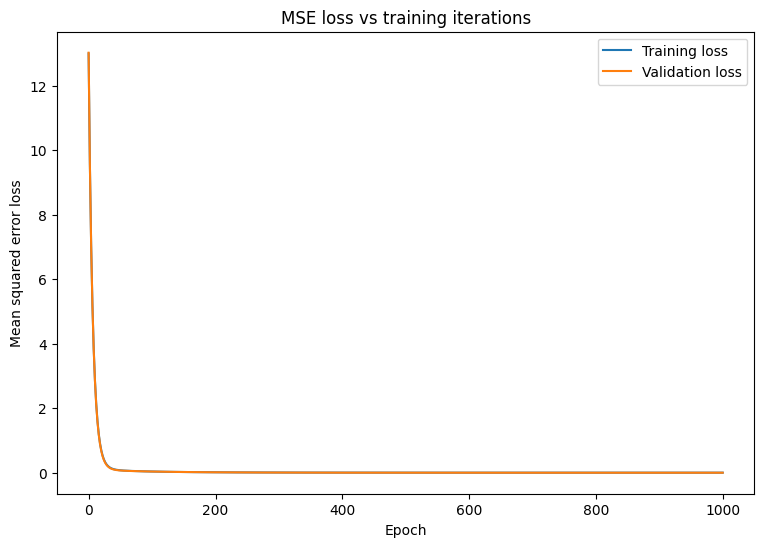

In [27]:
matplotlib.rcParams['figure.figsize'] = [9, 6]

plt.plot(range(EPOCHS), train_losses, label = "Training loss")
plt.plot(range(EPOCHS), val_losses, label = "Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error loss")
plt.legend()
plt.title("MSE loss vs training iterations");

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پیش‌بینی و ساختار خروجی برای نمونه‌های آزمون
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
اکنون نیاز است به‌ازای هر کدام از نمونه‌های آزمون (<code>X_test_norm</code>)، به‌کمک مدل خود (<code>regressor</code>) شانس پذیرش فرد را پیش‌بینی کنید. پیش‌بینی‌های مدل شما در ستون <code>Admission</code> دیتافریم <code>submission</code> ذخیره خواهد شد و توجه داشته باشید که ترتیب نمونه‌های آزمون باید حفظ شود.
</font>
</p>


<h3 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
معیار ارزیابی
</font>
</h3>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
برای ارزیابی عملکرد مدل شما بر روی نمونه‌های آزمون از معیار <code>MSE</code> استفاده می‌شود.
</font>
</p>


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font color="red"><b color='red'>توجه:</b></font>
<font face="vazir" size=3>
 جهت کسب امتیاز کامل نیاز است تا پاسخ شما <code>MSE</code> کمتر از <code>0.007</code> کسب کند.
</font>
</p>

In [28]:
predictions = regressor(X_test_norm).numpy() # TODO: make predictions on the X_test_norm data using the regressor (a numpy array)
submission = pd.DataFrame(predictions, columns=["Admission"])
submission

,Admission
0,0.652367
1,0.714405
2,0.929532
3,0.813773
4,0.573618
...,...
75,0.721048
76,0.692164
77,0.589998
78,0.883878


In [ ]:
#Now predicti my chance!

In [32]:
my_data = [[288, 83, 2, 4, 5, 7.6, 1]]
my_data_tf = tf.constant(my_data, dtype=tf.float32)
my_data_norm = normalizer.transform(my_data_tf)
my_prediction = regressor(my_data_norm)

print("Predicted admission probability:", my_prediction.numpy()[0])
print("Percentage:", my_prediction.numpy()[0] * 100, "%")

Predicted admission probability: 0.5064931
Percentage: 50.649307 %


<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
<b>سلول جواب‌ساز</b>
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    برای ساخته‌شدن فایل <code>result.zip</code> سلول‌های زیر را اجرا کنید. توجه داشته باشید که پیش از اجرای سلول زیر تغییرات اعمال شده در نت‌بوک را ذخیره کرده باشید (<code>ctrl+s</code>) تا در صورت نیاز به پشتیبانی امکان بررسی کد شما وجود داشته باشد. همچنین اگر از گوگل کولب استفاده می‌کنید، در صورت نیاز به پشتیبانی حتماً آخرین نسخه از نت‌بوک را به‌صورت دستی دانلود کرده و داخل فایل ارسالی قرار دهید یا لینک کولب را با ما به‌اشتراک بگذارید.
</font>
</p>

In [29]:
shape_b = regressor.variables[0].numpy().shape
shape_w = regressor.variables[1].numpy().shape
print("Bias shape:", shape_b)
print("Weights shape:", shape_w)

shape_mean = normalizer.mean.numpy().shape
shape_std = normalizer.std.numpy().shape
print("Mean shape:", shape_mean)
print("Standard deviation shape:", shape_std)

Bias shape: ()
Weights shape: (7, 1)
Mean shape: (7,)
Standard deviation shape: (7,)


In [30]:
import zipfile
import joblib
import os
import json

with open('linear_regression.json', 'w') as f:
    json.dump({
        "bias": shape_b,
        "weights": shape_w,
        "mean": shape_mean,
        "std": shape_std
    }, f)

if not os.path.exists(os.path.join(os.getcwd(), 'apply.ipynb')):
    %notebook -e apply.ipynb

def compress(file_names):
    print("File Paths:")
    print(file_names)
    compression = zipfile.ZIP_DEFLATED
    with zipfile.ZipFile("result.zip", mode="w") as zf:
        for file_name in file_names:
            zf.write('./' + file_name, file_name, compress_type=compression)

submission.to_csv('submission.csv', index=False)
file_names = ['submission.csv', 'apply.ipynb', 'linear_regression.json']
compress(file_names)

File Paths:
['submission.csv', 'apply.ipynb', 'linear_regression.json']
